In [2]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style= "darkgrid", color_codes = True)
from tensorflow.keras.applications import DenseNet121 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import  Dense, Dropout, Input, GlobalAveragePooling2D
from keras.regularizers import l2
import warnings
warnings.filterwarnings('ignore')
tf.config.optimizer.set_jit(False)
# Vérifier si GPU est disponible
if tf.config.list_physical_devices('GPU'):
    # Permettre la croissance de la mémoire GPU
    for gpu in tf.config.experimental.list_physical_devices('GPU'):
        tf.config.experimental.set_memory_growth(gpu, True)
print("GPU disponible:", tf.config.list_physical_devices('GPU'))

GPU disponible: []


In [3]:
# Define image size and other parameters
img_width, img_height = 128, 128
batchsize = 32
epochs = 6
num_of_class = 2
import tensorflow as tf
import os
import random

def create_balanced_three_class_dataset(directory, batch_size, img_size):
    normal_path = os.path.join(directory, 'NORMAL')
    pneumonia_path = os.path.join(directory, 'PNEUMONIA')

    # Récupération des fichiers et attribution des labels one-hot
    normal_files = [(os.path.join(normal_path, f), [1,0,0]) 
                    for f in os.listdir(normal_path) 
                    if f.endswith(('.jpeg', '.jpg', '.png'))]

    viral_files = [(os.path.join(pneumonia_path, f), [0,1,0]) 
                   for f in os.listdir(pneumonia_path) 
                   if 'virus' in f.lower() and f.endswith(('.jpeg', '.jpg', '.png'))]

    bacterial_files = [(os.path.join(pneumonia_path, f), [0,0,1]) 
                       for f in os.listdir(pneumonia_path) 
                       if 'bacteria' in f.lower() and f.endswith(('.jpeg', '.jpg', '.png'))]

    # Calcul du plus petit nombre d'images disponibles
    min_count = min(len(normal_files), len(viral_files), len(bacterial_files))

    # Équilibrer les classes
    random.shuffle(normal_files)
    random.shuffle(viral_files)
    random.shuffle(bacterial_files)

    normal_files = normal_files[:min_count]
    viral_files = viral_files[:min_count]
    bacterial_files = bacterial_files[:min_count]

    # Fusionner toutes les données
    all_data = normal_files + viral_files + bacterial_files
    random.shuffle(all_data)

    print(f"[{directory}] Normal: {len(normal_files)}, Viral: {len(viral_files)}, Bacterial: {len(bacterial_files)}")


    file_paths, labels = zip(*all_data)

    # Création du dataset
    def load_and_preprocess_image(file_path, label):
        img = tf.io.read_file(file_path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, img_size)
        img = img / 255.0
        return img, label

    dataset = tf.data.Dataset.from_tensor_slices((list(file_paths), list(labels)))
    dataset = dataset.map(load_and_preprocess_image)
    dataset = dataset.shuffle(buffer_size=len(all_data))
    dataset = dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

    return dataset


# Charger les datasets
img_size = (img_width, img_height)
train = create_balanced_three_class_dataset('chest_xray/train', batchsize, img_size)
validation = create_balanced_three_class_dataset('chest_xray/val', batchsize, img_size)
test = create_balanced_three_class_dataset('chest_xray/test', batchsize, img_size)

# Vérifier la forme des données
for images, labels in train.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Sample labels:", labels[0])  # Devrait montrer un vecteur one-hot de taille 3

[chest_xray/train] Normal: 1341, Viral: 1341, Bacterial: 1341
[chest_xray/val] Normal: 8, Viral: 8, Bacterial: 8
[chest_xray/test] Normal: 148, Viral: 148, Bacterial: 148
Images shape: (32, 128, 128, 3)
Labels shape: (32, 3)
Sample labels: tf.Tensor([0 1 0], shape=(3,), dtype=int32)


Format des labels: [0 1 0]
Label 0: [0.0, 1.0, 0.0]
Label 1: [1.0, 0.0, 0.0]
Label 2: [1.0, 0.0, 0.0]
Label 3: [0.0, 0.0, 1.0]


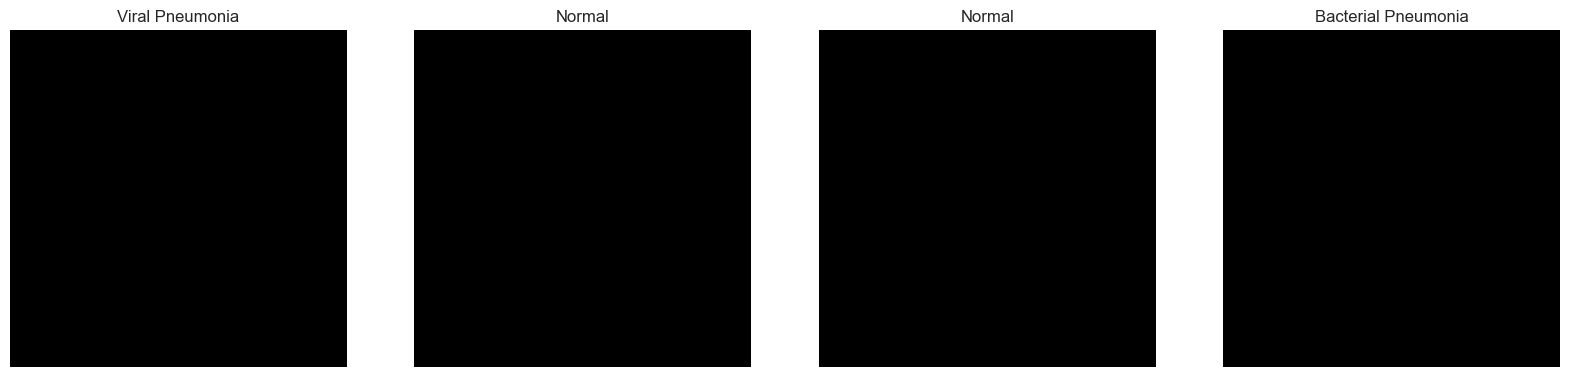

In [4]:
data_iterator = train.as_numpy_iterator()
batch = data_iterator.next()

# Afficher un exemple de label pour debug
print("Format des labels:", batch[1][0])

# Créer un dictionnaire pour convertir les labels one-hot en texte
label_dict = {
    '[1.0, 0.0, 0.0]': "Normal",
    '[0.0, 1.0, 0.0]': "Viral Pneumonia",
    '[0.0, 0.0, 1.0]': "Bacterial Pneumonia"
}

fig, ax = plt.subplots(ncols=4, figsize=(20,20))
for idx, img in enumerate(batch[0][:4]):
    ax[idx].imshow(img.astype(int))
    # Convertir le label en string avec le bon format
    label_str = str([float(x) for x in batch[1][idx].tolist()])
    print(f"Label {idx}:", label_str)  # Debug
    label = label_dict.get(label_str, "Unknown")
    ax[idx].title.set_text(label)
    ax[idx].axis('off')

plt.show()

In [5]:
from tensorflow.keras.utils import to_categorical
# Définir une taille fixe pour toutes les images
IMG_SIZE = (128, 128)  # Taille standard pour VGG16

# Extracting Features and Labels
x_train = []
y_train = []
x_val = []
y_val = []
x_test = []
y_test = []

# Fonction pour traiter un batch
def process_batch(batch):
    features, labels = batch
    features = tf.image.resize(features, IMG_SIZE)
    return features.numpy(), labels.numpy()

# Traiter les données d'entraînement
for batch in train:
    features, labels = process_batch(batch)
    x_train.extend(features)
    y_train.extend(labels)

# Traiter les données de test
for batch in test:
    features, labels = process_batch(batch)
    x_test.extend(features)
    y_test.extend(labels)

# Traiter les données de validation
for batch in validation:
    features, labels = process_batch(batch)
    x_val.extend(features)
    y_val.extend(labels)

# Convertir en arrays numpy
x_train = np.array(x_train, dtype=np.float32)
x_val = np.array(x_val, dtype=np.float32)
x_test = np.array(x_test, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)
y_val = np.array(y_val, dtype=np.float32)
y_test = np.array(y_test, dtype=np.float32)

# Normaliser les images
x_train = tf.image.resize(x_train, IMG_SIZE)
x_val = tf.image.resize(x_val, IMG_SIZE)
x_test = tf.image.resize(x_test, IMG_SIZE)


# Vérifier les shapes
print("Shape de x_train:", x_train.shape)
print("Shape de y_train:", y_train.shape)
print("Shape de x_val:", x_val.shape)
print("Shape de y_val:", y_val.shape)
print("Shape de x_test:", x_test.shape)
print("Shape de y_test:", y_test.shape)

# Vérifier les valeurs uniques dans les labels
print("\nValeurs uniques dans y_train:", np.unique(y_train, axis=0))

Shape de x_train: (4023, 128, 128, 3)
Shape de y_train: (4023, 3)
Shape de x_val: (24, 128, 128, 3)
Shape de y_val: (24, 3)
Shape de x_test: (444, 128, 128, 3)
Shape de y_test: (444, 3)

Valeurs uniques dans y_train: [[0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]]


In [6]:
# check the shapes of 'x_train' and 'y_train':
print("Shape of 'x_train':", x_train.shape)
print("Shape of 'y_train':", y_train.shape)
print("Shape of 'x_val':", x_val.shape)
print("Shape of 'y_val':", y_val.shape)
print("Shape of 'x_test':", x_test.shape)
print("Shape of 'y_test':", y_test.shape)

Shape of 'x_train': (4023, 128, 128, 3)
Shape of 'y_train': (4023, 3)
Shape of 'x_val': (24, 128, 128, 3)
Shape of 'y_val': (24, 3)
Shape of 'x_test': (444, 128, 128, 3)
Shape of 'y_test': (444, 3)


In [11]:
from tensorflow.keras.optimizers import Adam
def create_model():
    base_model = DenseNet121(
        weights='imagenet',
        include_top=False,
        input_shape=(128, 128, 3)
    )

    base_model.trainable = False  # gel des poids du backbone

    model = Sequential([
        base_model,
        GlobalAveragePooling2D(),
        Dropout(0.4),
        Dense(256, activation='relu', kernel_regularizer=l2(0.01)),
        Dropout(0.3),
        Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
        Dense(3, activation='softmax')
    ])

    optimizer = Adam(learning_rate=0.0001)

    model.compile(
        optimizer=optimizer,
        loss='categorical_crossentropy',
        metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
    )

    model.summary()
    return model

Fold 1/5


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 4, 4, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,333,187 (27.97 MB)

 Trainable params: 295,683 (1.13 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

Epoch 1/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 88s 767ms/step - accuracy: 0.3728 - loss: 7.0451 - precision: 0.3734 - recall: 0.3150 - val_accuracy: 0.7019 - val_loss: 5.5923 - val_precision: 0.7578 - val_recall: 0.5752 - learning_rate: 1.0000e-04
Epoch 2/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 59s 583ms/step - accuracy: 0.5196 - loss: 5.7336 - precision: 0.5419 - recall: 0.4398 - val_accuracy: 0.7329 - val_loss: 4.8671 - val_precision: 0.7704 - val_recall: 0.6335 - learning_rate: 1.0000e-04
Epoch 3/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 59s 586ms/step - accuracy: 0.6063 - loss: 4.9350 - precision: 0.6309 - recall: 0.5390 - val_accuracy: 0.7441 - val_loss: 4.3277 - val_precision: 0.7745 - val_recall: 0.6783 - learning_rate: 1.0000e-04
Epoch 4/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 59s 586ms/step - accuracy: 0.6231 - loss: 4.4504 - precision: 0.6650 - recall: 0.5626 - val_accuracy: 0.7429 - val_loss: 3.9450 - val_precision: 0.7666 - val_recall: 0.6894 - learning_rate: 1.0000e-04
Epoch 5/20
101/101 ━━━━━━━━━━━━━━━━━

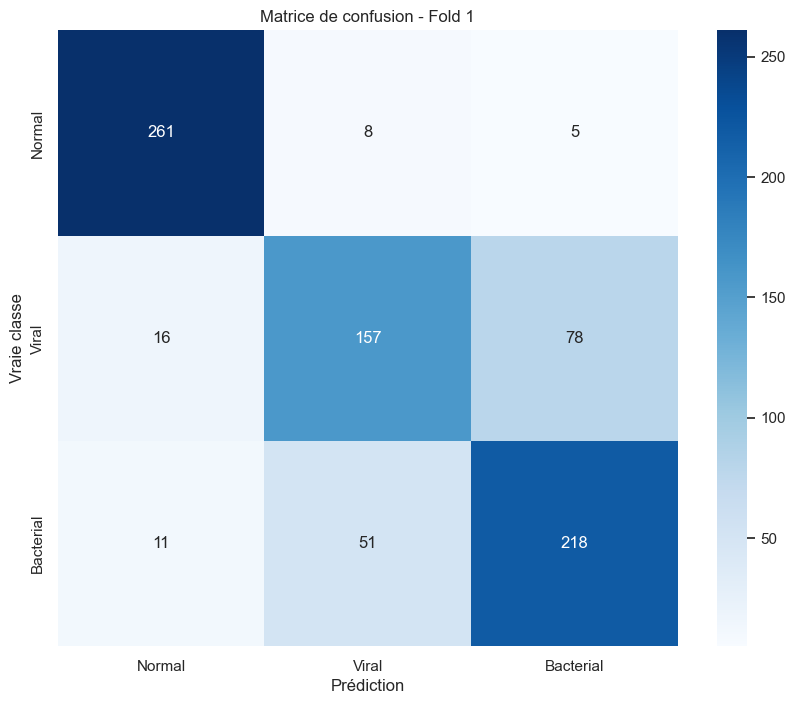


Métriques détaillées pour le Fold 1:

Classe: Normal
True Positives (TP): 261
True Negatives (TN): 504
False Positives (FP): 27
False Negatives (FN): 13
Precision: 0.9062
Recall: 0.9526

Classe: Viral
True Positives (TP): 157
True Negatives (TN): 495
False Positives (FP): 59
False Negatives (FN): 94
Precision: 0.7269
Recall: 0.6255

Classe: Bacterial
True Positives (TP): 218
True Negatives (TN): 442
False Positives (FP): 83
False Negatives (FN): 62
Precision: 0.7243
Recall: 0.7786

Rapport de classification détaillé:
              precision    recall  f1-score   support

      Normal       0.91      0.95      0.93       274
       Viral       0.73      0.63      0.67       251
   Bacterial       0.72      0.78      0.75       280

    accuracy                           0.79       805
   macro avg       0.79      0.79      0.78       805
weighted avg       0.79      0.79      0.79       805



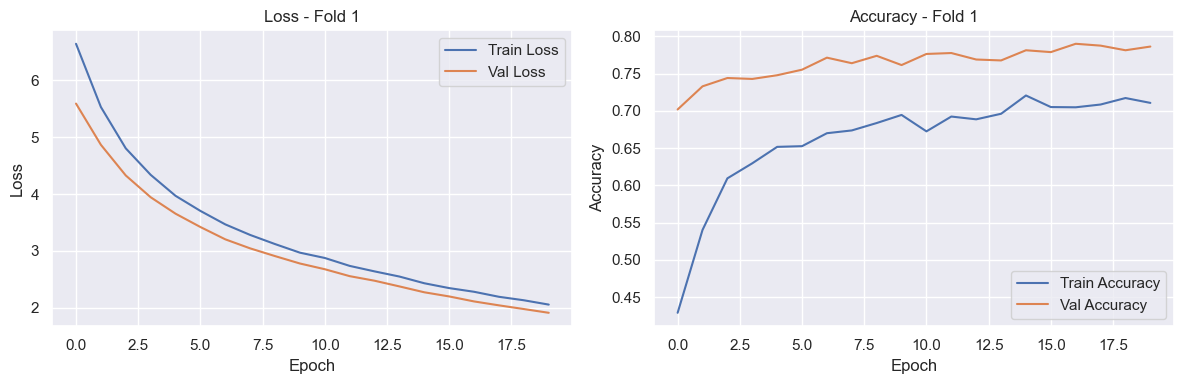

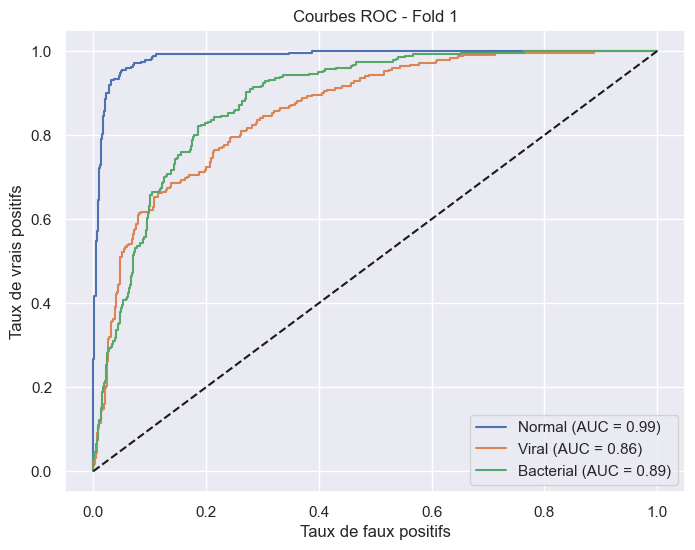

Fold 2/5


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 4, 4, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,333,187 (27.97 MB)

 Trainable params: 295,683 (1.13 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

Epoch 1/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 72s 608ms/step - accuracy: 0.3862 - loss: 6.9597 - precision_1: 0.3898 - recall_1: 0.3204 - val_accuracy: 0.6932 - val_loss: 5.6012 - val_precision_1: 0.7581 - val_recall_1: 0.5491 - learning_rate: 1.0000e-04
Epoch 2/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 59s 583ms/step - accuracy: 0.5566 - loss: 5.6329 - precision_1: 0.5909 - recall_1: 0.4866 - val_accuracy: 0.7205 - val_loss: 4.8160 - val_precision_1: 0.7571 - val_recall_1: 0.6311 - learning_rate: 1.0000e-04
Epoch 3/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 62s 614ms/step - accuracy: 0.6096 - loss: 4.8596 - precision_1: 0.6427 - recall_1: 0.5533 - val_accuracy: 0.7466 - val_loss: 4.2473 - val_precision_1: 0.7768 - val_recall_1: 0.6832 - learning_rate: 1.0000e-04
Epoch 4/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 62s 620ms/step - accuracy: 0.6281 - loss: 4.3163 - precision_1: 0.6652 - recall_1: 0.5672 - val_accuracy: 0.7602 - val_loss: 3.8359 - val_precision_1: 0.7888 - val_recall_1: 0.7006 - learning_rate: 1.0000e-04
Epoc

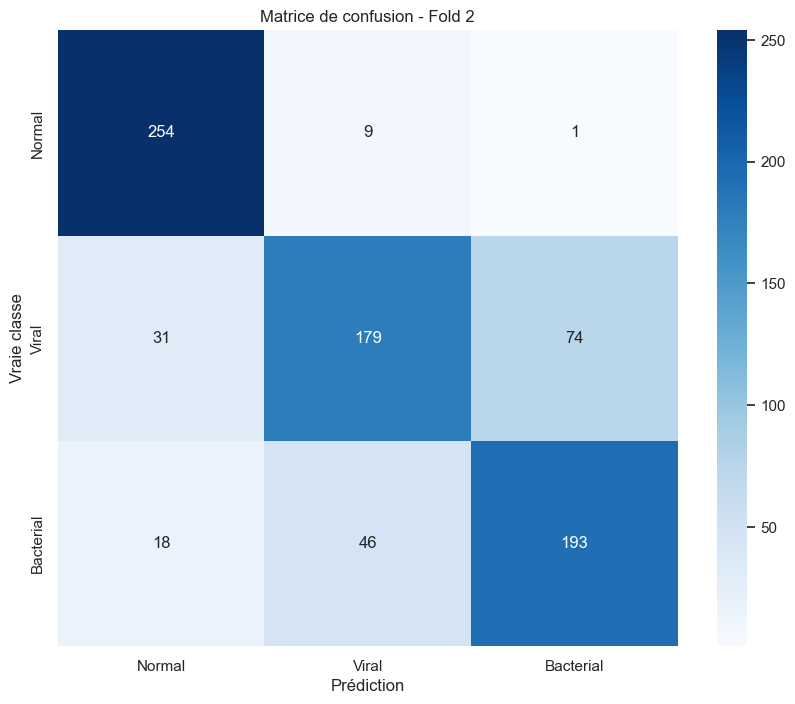


Métriques détaillées pour le Fold 2:

Classe: Normal
True Positives (TP): 254
True Negatives (TN): 492
False Positives (FP): 49
False Negatives (FN): 10
Precision: 0.8383
Recall: 0.9621

Classe: Viral
True Positives (TP): 179
True Negatives (TN): 466
False Positives (FP): 55
False Negatives (FN): 105
Precision: 0.7650
Recall: 0.6303

Classe: Bacterial
True Positives (TP): 193
True Negatives (TN): 473
False Positives (FP): 75
False Negatives (FN): 64
Precision: 0.7201
Recall: 0.7510

Rapport de classification détaillé:
              precision    recall  f1-score   support

      Normal       0.84      0.96      0.90       264
       Viral       0.76      0.63      0.69       284
   Bacterial       0.72      0.75      0.74       257

    accuracy                           0.78       805
   macro avg       0.77      0.78      0.77       805
weighted avg       0.77      0.78      0.77       805



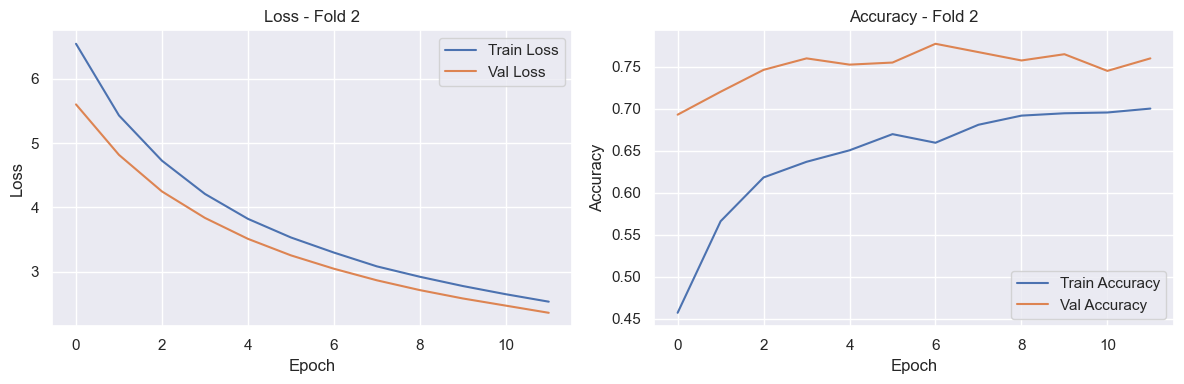

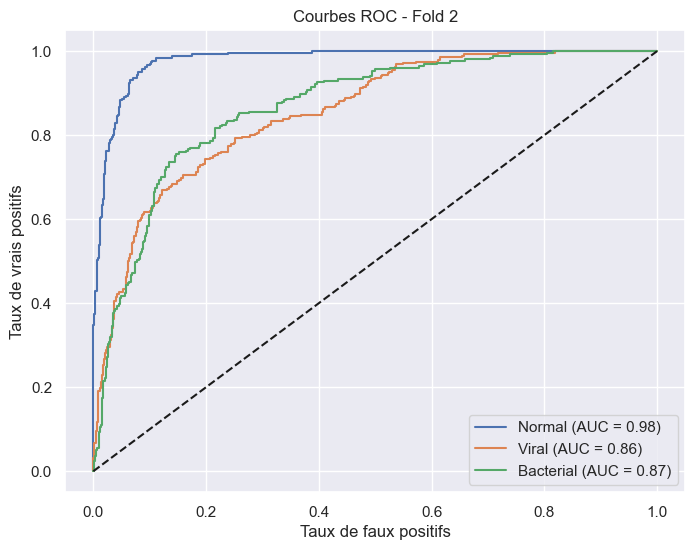

Fold 3/5


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 4, 4, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,333,187 (27.97 MB)

 Trainable params: 295,683 (1.13 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

Epoch 1/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 91s 784ms/step - accuracy: 0.3944 - loss: 6.9492 - precision_2: 0.4132 - recall_2: 0.3275 - val_accuracy: 0.6832 - val_loss: 5.5944 - val_precision_2: 0.7580 - val_recall_2: 0.5329 - learning_rate: 1.0000e-04
Epoch 2/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 73s 720ms/step - accuracy: 0.5638 - loss: 5.6046 - precision_2: 0.6023 - recall_2: 0.4832 - val_accuracy: 0.7205 - val_loss: 4.8220 - val_precision_2: 0.7618 - val_recall_2: 0.6435 - learning_rate: 1.0000e-04
Epoch 3/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 71s 700ms/step - accuracy: 0.6282 - loss: 4.8207 - precision_2: 0.6653 - recall_2: 0.5559 - val_accuracy: 0.7242 - val_loss: 4.2706 - val_precision_2: 0.7514 - val_recall_2: 0.6683 - learning_rate: 1.0000e-04
Epoch 4/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 69s 685ms/step - accuracy: 0.6528 - loss: 4.2935 - precision_2: 0.6854 - recall_2: 0.5898 - val_accuracy: 0.7230 - val_loss: 3.8542 - val_precision_2: 0.7648 - val_recall_2: 0.6745 - learning_rate: 1.0000e-04
Epoc

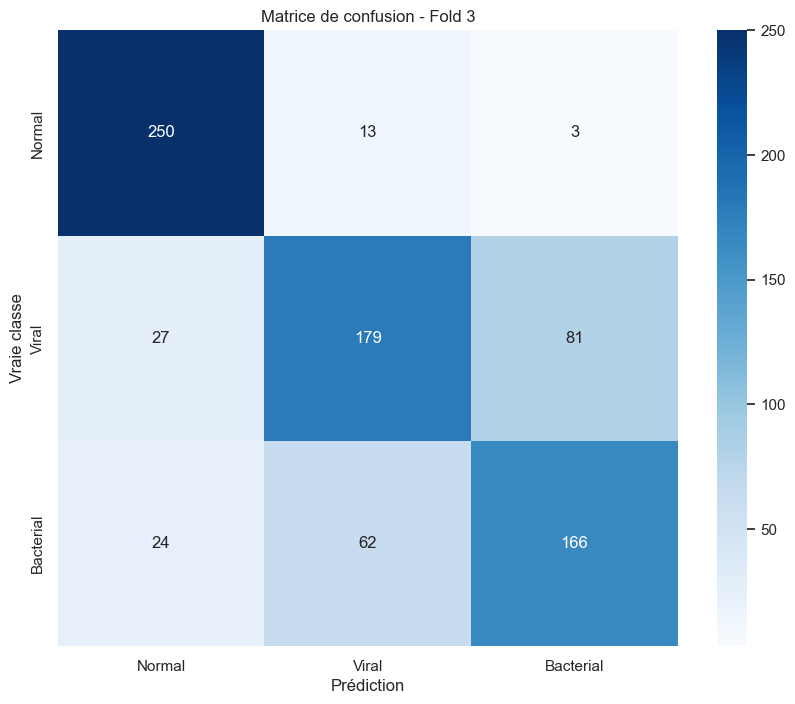


Métriques détaillées pour le Fold 3:

Classe: Normal
True Positives (TP): 250
True Negatives (TN): 488
False Positives (FP): 51
False Negatives (FN): 16
Precision: 0.8306
Recall: 0.9398

Classe: Viral
True Positives (TP): 179
True Negatives (TN): 443
False Positives (FP): 75
False Negatives (FN): 108
Precision: 0.7047
Recall: 0.6237

Classe: Bacterial
True Positives (TP): 166
True Negatives (TN): 469
False Positives (FP): 84
False Negatives (FN): 86
Precision: 0.6640
Recall: 0.6587

Rapport de classification détaillé:
              precision    recall  f1-score   support

      Normal       0.83      0.94      0.88       266
       Viral       0.70      0.62      0.66       287
   Bacterial       0.66      0.66      0.66       252

    accuracy                           0.74       805
   macro avg       0.73      0.74      0.73       805
weighted avg       0.73      0.74      0.73       805



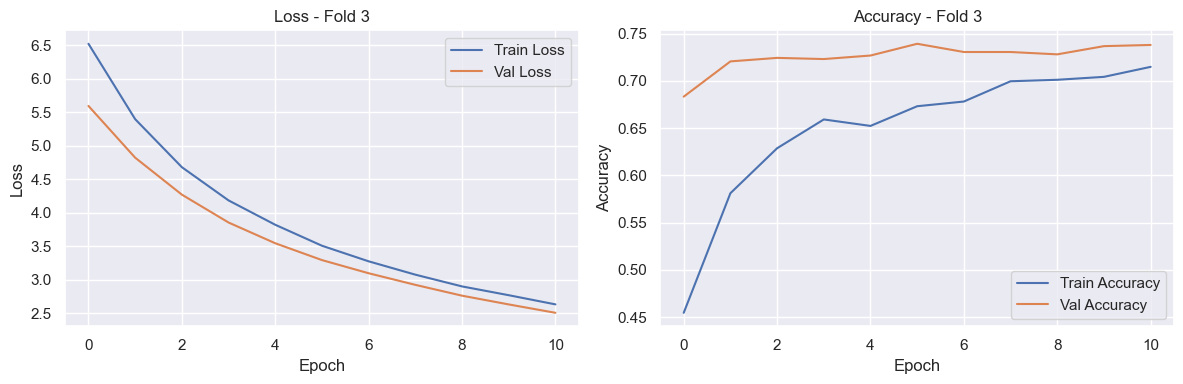

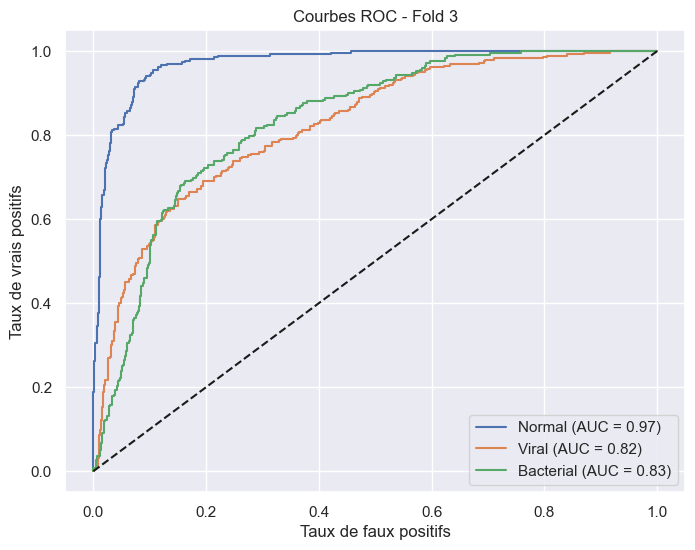

Fold 4/5


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 4, 4, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,333,187 (27.97 MB)

 Trainable params: 295,683 (1.13 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

Epoch 1/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 94s 812ms/step - accuracy: 0.4143 - loss: 6.9280 - precision_3: 0.4207 - recall_3: 0.3526 - val_accuracy: 0.6542 - val_loss: 5.6044 - val_precision_3: 0.7213 - val_recall_3: 0.5473 - learning_rate: 1.0000e-04
Epoch 2/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 65s 645ms/step - accuracy: 0.5702 - loss: 5.6428 - precision_3: 0.5965 - recall_3: 0.5006 - val_accuracy: 0.6953 - val_loss: 4.8675 - val_precision_3: 0.7603 - val_recall_3: 0.6194 - learning_rate: 1.0000e-04
Epoch 3/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 66s 650ms/step - accuracy: 0.6058 - loss: 4.9171 - precision_3: 0.6479 - recall_3: 0.5510 - val_accuracy: 0.6990 - val_loss: 4.3274 - val_precision_3: 0.7374 - val_recall_3: 0.6356 - learning_rate: 1.0000e-04
Epoch 4/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 62s 614ms/step - accuracy: 0.6266 - loss: 4.3865 - precision_3: 0.6494 - recall_3: 0.5686 - val_accuracy: 0.7139 - val_loss: 3.9232 - val_precision_3: 0.7707 - val_recall_3: 0.6480 - learning_rate: 1.0000e-04
Epoc

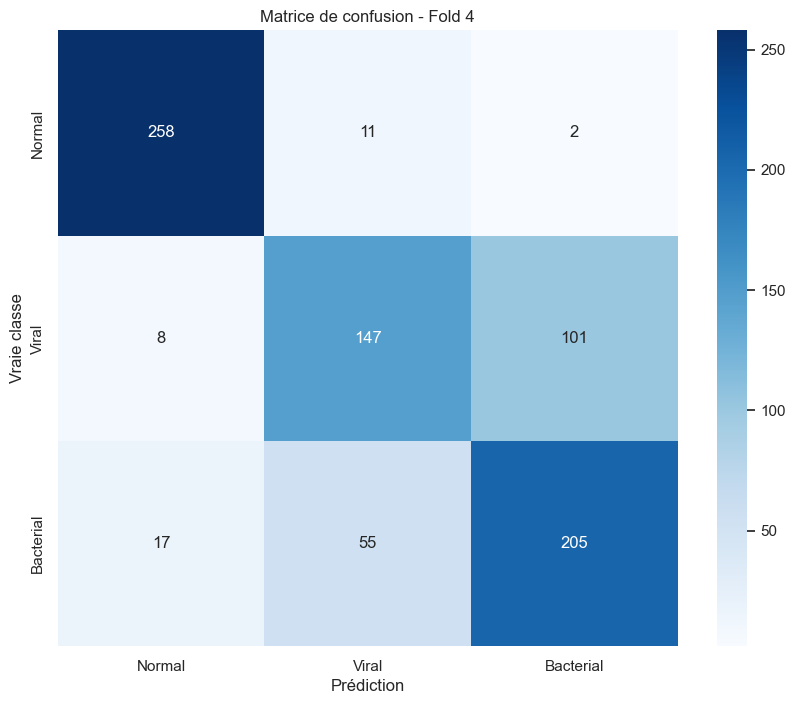


Métriques détaillées pour le Fold 4:

Classe: Normal
True Positives (TP): 258
True Negatives (TN): 508
False Positives (FP): 25
False Negatives (FN): 13
Precision: 0.9117
Recall: 0.9520

Classe: Viral
True Positives (TP): 147
True Negatives (TN): 482
False Positives (FP): 66
False Negatives (FN): 109
Precision: 0.6901
Recall: 0.5742

Classe: Bacterial
True Positives (TP): 205
True Negatives (TN): 424
False Positives (FP): 103
False Negatives (FN): 72
Precision: 0.6656
Recall: 0.7401

Rapport de classification détaillé:
              precision    recall  f1-score   support

      Normal       0.91      0.95      0.93       271
       Viral       0.69      0.57      0.63       256
   Bacterial       0.67      0.74      0.70       277

    accuracy                           0.76       804
   macro avg       0.76      0.76      0.75       804
weighted avg       0.76      0.76      0.76       804



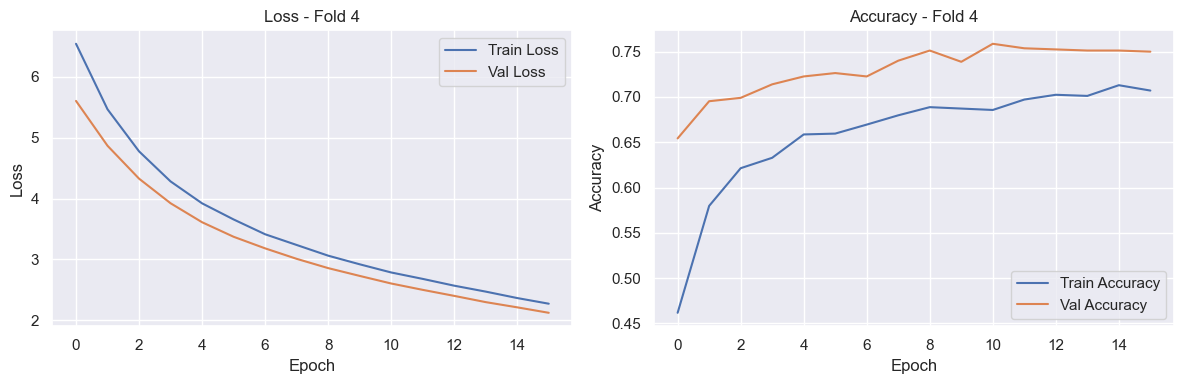

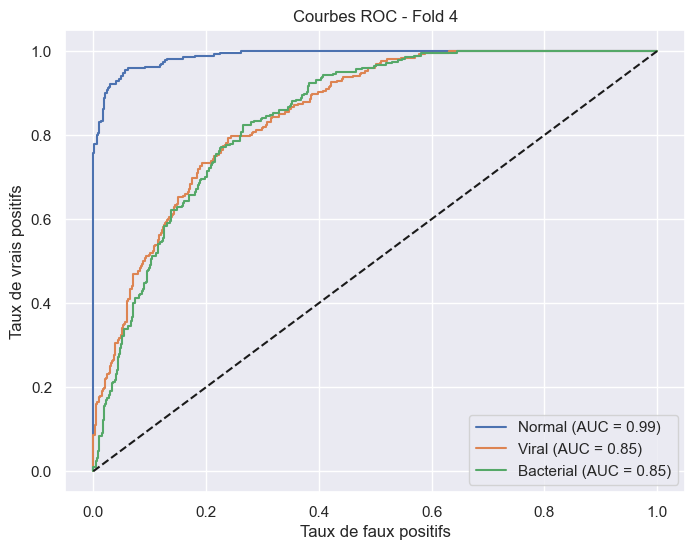

Fold 5/5


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 4, 4, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,333,187 (27.97 MB)

 Trainable params: 295,683 (1.13 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

Epoch 1/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 80s 688ms/step - accuracy: 0.3836 - loss: 7.1235 - precision_4: 0.3952 - recall_4: 0.3286 - val_accuracy: 0.6965 - val_loss: 5.5947 - val_precision_4: 0.7662 - val_recall_4: 0.5585 - learning_rate: 1.0000e-04
Epoch 2/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 67s 661ms/step - accuracy: 0.5573 - loss: 5.6480 - precision_4: 0.6025 - recall_4: 0.4819 - val_accuracy: 0.7313 - val_loss: 4.8199 - val_precision_4: 0.7726 - val_recall_4: 0.6592 - learning_rate: 1.0000e-04
Epoch 3/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 66s 652ms/step - accuracy: 0.6072 - loss: 4.8750 - precision_4: 0.6450 - recall_4: 0.5412 - val_accuracy: 0.7400 - val_loss: 4.2799 - val_precision_4: 0.7771 - val_recall_4: 0.6766 - learning_rate: 1.0000e-04
Epoch 4/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 68s 674ms/step - accuracy: 0.6551 - loss: 4.3276 - precision_4: 0.6896 - recall_4: 0.5867 - val_accuracy: 0.7550 - val_loss: 3.8736 - val_precision_4: 0.7823 - val_recall_4: 0.6928 - learning_rate: 1.0000e-04
Epoc

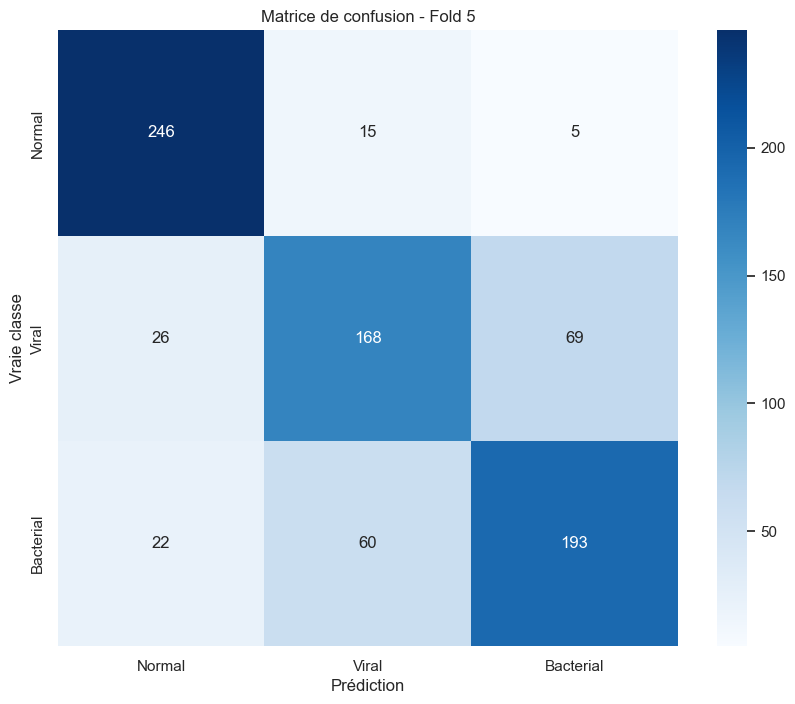


Métriques détaillées pour le Fold 5:

Classe: Normal
True Positives (TP): 246
True Negatives (TN): 490
False Positives (FP): 48
False Negatives (FN): 20
Precision: 0.8367
Recall: 0.9248

Classe: Viral
True Positives (TP): 168
True Negatives (TN): 466
False Positives (FP): 75
False Negatives (FN): 95
Precision: 0.6914
Recall: 0.6388

Classe: Bacterial
True Positives (TP): 193
True Negatives (TN): 455
False Positives (FP): 74
False Negatives (FN): 82
Precision: 0.7228
Recall: 0.7018

Rapport de classification détaillé:
              precision    recall  f1-score   support

      Normal       0.84      0.92      0.88       266
       Viral       0.69      0.64      0.66       263
   Bacterial       0.72      0.70      0.71       275

    accuracy                           0.75       804
   macro avg       0.75      0.76      0.75       804
weighted avg       0.75      0.75      0.75       804



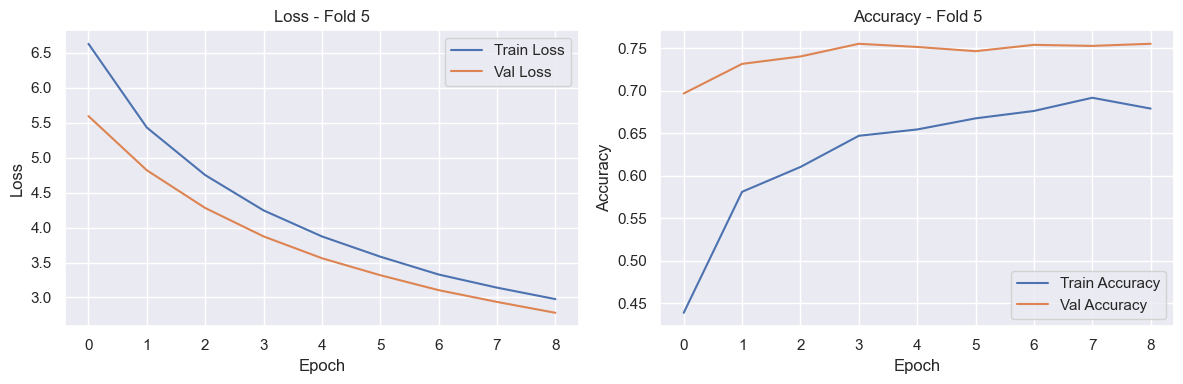

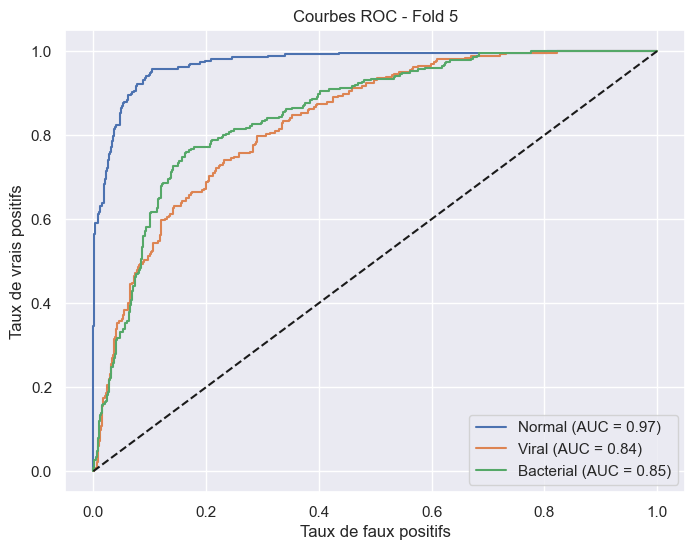


Résultats finaux:
Score moyen: 0.7641 (+/- 0.0179)


In [12]:
from sklearn.model_selection import KFold
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# Convertir les données en numpy arrays si ce n'est pas déjà fait
x_train_np = x_train.numpy() if isinstance(x_train, tf.Tensor) else x_train
y_train_np = y_train.numpy() if isinstance(y_train, tf.Tensor) else y_train

# Définir le nombre de folds
n_folds = 5
batch_size = 32
epochs = 20
kf = KFold(n_splits=n_folds, shuffle=True, random_state=42)
class_names = ['Normal', 'Viral', 'Bacterial']
# Boucle de validation croisée
val_scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(x_train_np)):
    print(f'Fold {fold + 1}/{n_folds}')
    
    model = create_model()
    
    # Utiliser les arrays numpy pour l'indexation
    x_train_fold = x_train_np[train_idx]
    y_train_fold = y_train_np[train_idx]
    x_val_fold = x_train_np[val_idx]
    y_val_fold = y_train_np[val_idx]
    
    # Convertir en tensors pour l'entraînement si nécessaire
    x_train_fold = tf.convert_to_tensor(x_train_fold)
    y_train_fold = tf.convert_to_tensor(y_train_fold)
    x_val_fold = tf.convert_to_tensor(x_val_fold)
    y_val_fold = tf.convert_to_tensor(y_val_fold)
    
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=5,
        restore_best_weights=True
    )
    
    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=0.00001
    )

    history = model.fit(
        x_train_fold,
        y_train_fold,
        validation_data=(x_val_fold, y_val_fold),
        epochs=epochs,
        batch_size=batch_size,
        verbose=1,
        callbacks=[early_stopping, reduce_lr]
    )
    
    val_score = model.evaluate(x_val_fold, y_val_fold, verbose=0)
    val_scores.append(val_score[1])
    
    print(f"Fold {fold + 1} - Accuracy: {val_score[1]:.4f}")
    
     # Matrice de confusion avec plus de détails
    y_pred = model.predict(x_val_fold)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = np.argmax(y_val_fold, axis=1)
    
    
    cm = confusion_matrix(y_true_classes, y_pred_classes)
    
    # Calculer TP, TN, FP, FN pour chaque classe
    n_classes = 3
    metrics = {}
    
    for i in range(n_classes):
        TP = cm[i, i]
        FP = np.sum(cm[:, i]) - TP
        FN = np.sum(cm[i, :]) - TP
        TN = np.sum(cm) - TP - FP - FN
        
        metrics[class_names[i]] = {
            'TP': TP,
            'TN': TN,
            'FP': FP,
            'FN': FN,
            'Precision': TP / (TP + FP) if (TP + FP) > 0 else 0,
            'Recall': TP / (TP + FN) if (TP + FN) > 0 else 0
        }
    
    # Afficher la matrice de confusion
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names,
                yticklabels=class_names)
    plt.title(f'Matrice de confusion - Fold {fold + 1}')
    plt.ylabel('Vraie classe')
    plt.xlabel('Prédiction')
    plt.show()
    
    # Afficher les métriques détaillées
    print(f"\nMétriques détaillées pour le Fold {fold + 1}:")
    for classe, m in metrics.items():
        print(f"\nClasse: {classe}")
        print(f"True Positives (TP): {m['TP']}")
        print(f"True Negatives (TN): {m['TN']}")
        print(f"False Positives (FP): {m['FP']}")
        print(f"False Negatives (FN): {m['FN']}")
        print(f"Precision: {m['Precision']:.4f}")
        print(f"Recall: {m['Recall']:.4f}")
    
    # Afficher le rapport de classification complet
    print("\nRapport de classification détaillé:")
    print(classification_report(y_true_classes, y_pred_classes, 
                              target_names=class_names))

    # --- Courbes d'entraînement/validation ---
    plt.figure(figsize=(12, 4))

    # Courbe de loss
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    # Courbe d'accuracy
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1}')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

    # --- Courbe ROC par classe ---
    # Assurer que les labels sont one-hot encodés
    from sklearn.preprocessing import label_binarize
    from sklearn.metrics import roc_curve, auc

    if y_val_fold.shape[1] != len(class_names):  # besoin d'encoder
        y_val_bin = label_binarize(np.argmax(y_val_fold, axis=1), classes=[0, 1, 2])
    else:
        y_val_bin = y_val_fold.numpy() if isinstance(y_val_fold, tf.Tensor) else y_val_fold

    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(len(class_names)):
        fpr[i], tpr[i], _ = roc_curve(y_val_bin[:, i], y_pred[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    plt.figure(figsize=(8, 6))
    for i in range(len(class_names)):
        plt.plot(fpr[i], tpr[i], label=f"{class_names[i]} (AUC = {roc_auc[i]:.2f})")
    plt.plot([0, 1], [0, 1], 'k--')
    plt.title(f'Courbes ROC - Fold {fold + 1}')
    plt.xlabel('Taux de faux positifs')
    plt.ylabel('Taux de vrais positifs')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()
                              
   

print("\nRésultats finaux:")
print(f"Score moyen: {np.mean(val_scores):.4f} (+/- {np.std(val_scores):.4f})")

In [13]:
model.save('CNN_model.h5')